## In This project we are going to Predict weather a payment is a fraud or not  

Import libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

REading the csb through the pandas

In [ ]:
data = pd.read_csv("/content/paysim dataset.csv", on_bad_lines="skip")

lets see about our data

In [ ]:
data.shape

(42271, 11)

So there are 11 features and 6294750 columns

In [ ]:
data.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0.0,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0.0,0.0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1.0,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1.0,0.0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0.0,0.0


## PaySim Dataset Features Description

* **`step`**: Maps a unit of time in the real world. In this simulation, 1 step represents 1 hour (totaling 744 steps for a 30-day simulation)[cite: 2].
* **`type`**: The category of the transaction (`CASH_IN`, `CASH_OUT`, `DEBIT`, `PAYMENT`, or `TRANSFER`)[cite: 2].
* **`amount`**: The monetary amount of the transaction[cite: 2].
* **`nameOrig`**: Unique identifier for the customer who initiated the transaction (starts with `C`)[cite: 2].
* **`oldbalanceOrg`**: The sender's account balance before the transaction[cite: 2].
* **`newbalanceOrg`**: The sender's account balance after the transaction[cite: 2].
* **`nameDest`**: Unique identifier for the recipient. Starts with `C` for customers or `M` for merchants[cite: 2].
* **`oldbalanceDest`**: The recipient's account balance before the transaction (note: values are typically `0.0` for merchants)[cite: 2].
* **`newbalanceDest`**: The recipient's account balance after the transaction (note: values are typically `0.0` for merchants)[cite: 2].
* **`isFraud`**: The target label indicating whether a transaction is fraudulent (`1`) or legitimate (`0`)[cite: 2].
* **`isFlaggedFraud`**: A business-rule flag that triggers (`1`) if an unauthorized attempt tries to transfer more than 200,000 in a single transaction (typically dropped during modeling)[cite: 2].

In [ ]:
data.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,42271.000000,4.227100e+04,4.227100e+04,4.227100e+04,4.227000e+04,4.227000e+04,42270.000000,42270.0
mean,7.171087,1.490108e+05,7.727734e+05,7.874065e+05,8.450982e+05,1.158405e+06,0.002224,0.0
std,2.118037,3.145005e+05,2.284003e+06,2.321941e+06,2.466743e+06,2.960508e+06,0.047105,0.0
min,1.000000,1.770000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0
25%,7.000000,7.031875e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0
50%,8.000000,2.751283e+04,1.856733e+04,3.339900e+02,0.000000e+00,0.000000e+00,0.000000,0.0
75%,8.000000,1.794321e+05,1.421965e+05,1.500335e+05,4.337969e+05,8.013660e+05,0.000000,0.0
max,9.000000,1.000000e+07,2.854724e+07,2.861740e+07,2.958454e+07,3.130692e+07,1.000000,0.0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42271 entries, 0 to 42270
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            42271 non-null  int64  
 1   type            42271 non-null  object 
 2   amount          42271 non-null  float64
 3   nameOrig        42271 non-null  object 
 4   oldbalanceOrg   42271 non-null  float64
 5   newbalanceOrig  42271 non-null  float64
 6   nameDest        42271 non-null  object 
 7   oldbalanceDest  42270 non-null  float64
 8   newbalanceDest  42270 non-null  float64
 9   isFraud         42270 non-null  float64
 10  isFlaggedFraud  42270 non-null  float64
dtypes: float64(7), int64(1), object(3)
memory usage: 3.5+ MB


In [ ]:
(data.isna().sum()/6294750)*100

,0
step,0.000000
type,0.000000
amount,0.000000
nameOrig,0.000000
oldbalanceOrg,0.000000
newbalanceOrig,0.000000
nameDest,0.000000
oldbalanceDest,0.000016
newbalanceDest,0.000016
isFraud,0.000016


Since there are 1 ,2,2,4,9 missing values in the data set we are going to fill them with the median and remove the rows containig null values in is fraud . and we are going to drop the isFlagged column from the data Or we cann just drop all the rows containing the null values since the data set is very big and it will not get affted by removing 12 to 13 rows.

In [ ]:
data.dropna(inplace=True)

In [ ]:
data.isna().sum(),data.shape

(step              0
 type              0
 amount            0
 nameOrig          0
 oldbalanceOrg     0
 newbalanceOrig    0
 nameDest          0
 oldbalanceDest    0
 newbalanceDest    0
 isFraud           0
 isFlaggedFraud    0
 dtype: int64,
 (42270, 11))

total 18 we have droped  from the data set.

Now we are goin to remove some unneccesary column that may affect our predictions

In [ ]:
data.columns


Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

In [ ]:
data["isFraud"].value_counts()

,count
isFraud,
0.0,42176
1.0,94


<Axes: xlabel='isFraud', ylabel='count'>

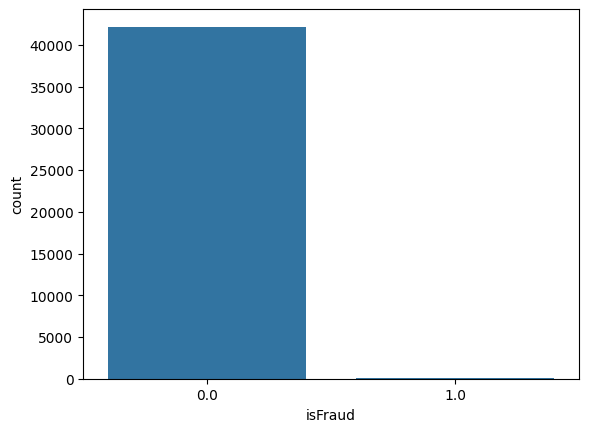

In [ ]:
sns.countplot(x=data["isFraud"])

Text(0.5, 1.0, 'Frequency of Transaction type')

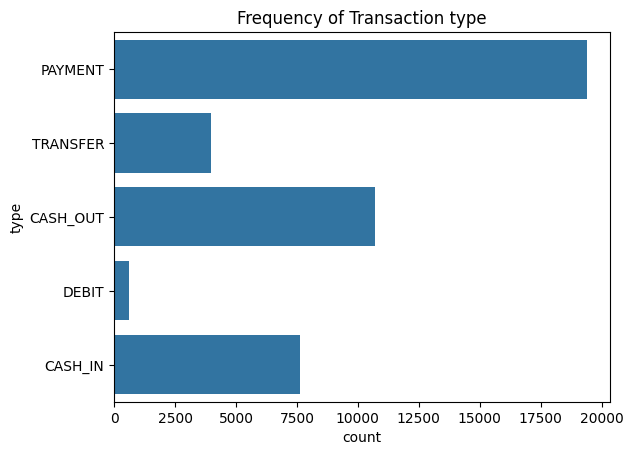

In [ ]:
sns.countplot(data["type"])
plt.title("Frequency of Transaction type")

In [ ]:
fraud_transaction=data.groupby("type")["isFraud"].mean()*100

<BarContainer object of 5 artists>

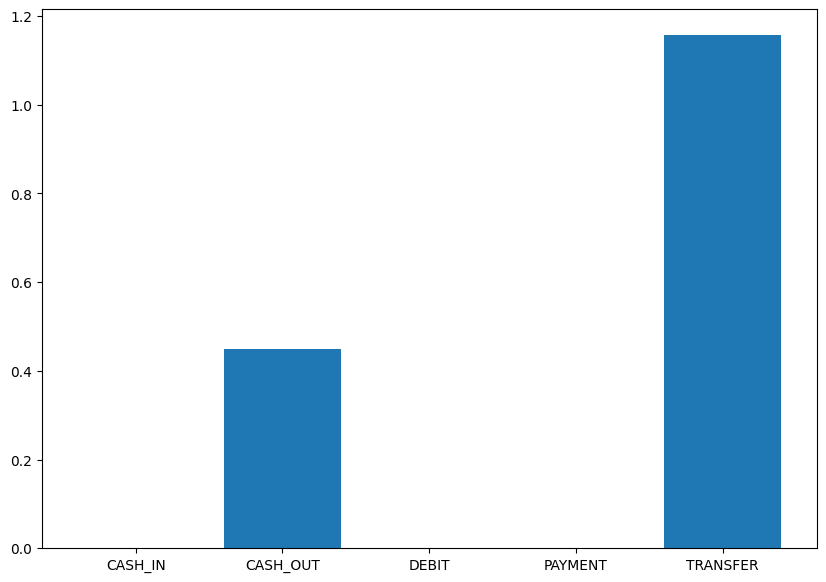

In [ ]:
plt.figure(figsize=(10,7))

plt.bar(fraud_transaction.index,fraud_transaction.values)


Here we can see that the most of the fruauds are happening in cashout and transfer, and no fraud in cash in , cash t , debit, payment_out , payment so we are going to remove that rows where type is not equal tt cashout or transfer

In [ ]:
data=data[(data["type"]=="CASH_OUT")  | ( data["type"]=="TRANSFER")]

In [ ]:
data.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
2,1,TRANSFER,181.00,C1305486145,181.0,0.0,C553264065,0.0,0.00,1.0,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.0,C38997010,21182.0,0.00,1.0,0.0
15,1,CASH_OUT,229133.94,C905080434,15325.0,0.0,C476402209,5083.0,51513.44,0.0,0.0
19,1,TRANSFER,215310.30,C1670993182,705.0,0.0,C1100439041,22425.0,0.00,0.0,0.0
24,1,TRANSFER,311685.89,C1984094095,10835.0,0.0,C932583850,6267.0,2719172.89,0.0,0.0


In [ ]:
data.shape

(14662, 11)

In [ ]:
data.isFraud.value_counts()

,count
isFraud,
0.0,14568
1.0,94


no. of transaction where the amount transfered is 0

In [ ]:
sum(data["amount"]==0)

0

no. of transaction where the amount transfered is negative

In [ ]:
sum(data["amount"]<0)

0

In the PaySim financial dataset, each column is dropped for specific machine learning reasons:

nameOrig and nameDest (Customer IDs/Names): These represent unique customer account identifiers (like C123456789). They are strings with high cardinality (thousands of unique values) and carry no meaningful mathematical pattern for fraud. If left in, tree-based models might overfit to specific customer IDs rather than learning general fraudulent behavior.

isFlaggedFraud: This column represents the business's built-in rule-based system (which flags transfers greater than 200,000). Because it is a deterministic rule rather than a true target label (which is isFraud), keeping it can cause data leakage, allowing the model to simply memorize the rule instead of learning predictive patterns.

step: This represents a unit of time (1 step = 1 hour). While time can sometimes matter, in PaySim, fraud is distributed across arbitrary steps without a strong cyclical or linear trend that benefits standard neural networks or basic classifiers unless heavily engineered, so it's often dropped to simplify the feature space.

In [ ]:
data_cleaned=data.drop(labels=["nameOrig","nameDest","isFlaggedFraud","step"],axis=1)

In [ ]:
data_cleaned.head()

,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
2,TRANSFER,181.00,181.0,0.0,0.0,0.00,1.0
3,CASH_OUT,181.00,181.0,0.0,21182.0,0.00,1.0
15,CASH_OUT,229133.94,15325.0,0.0,5083.0,51513.44,0.0
19,TRANSFER,215310.30,705.0,0.0,22425.0,0.00,0.0
24,TRANSFER,311685.89,10835.0,0.0,6267.0,2719172.89,0.0


In [ ]:
data_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14662 entries, 2 to 42269
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   type            14662 non-null  object 
 1   amount          14662 non-null  float64
 2   oldbalanceOrg   14662 non-null  float64
 3   newbalanceOrig  14662 non-null  float64
 4   oldbalanceDest  14662 non-null  float64
 5   newbalanceDest  14662 non-null  float64
 6   isFraud         14662 non-null  float64
dtypes: float64(6), object(1)
memory usage: 916.4+ KB


In [ ]:
data_cleaned["type"].unique()

array(['TRANSFER', 'CASH_OUT'], dtype=object)

In [ ]:
data_cleaned=pd.get_dummies(data_cleaned,columns=["type"],drop_first=False)

In [ ]:
data_cleaned.head()

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,type_CASH_OUT,type_TRANSFER
2,181.00,181.0,0.0,0.0,0.00,1.0,False,True
3,181.00,181.0,0.0,21182.0,0.00,1.0,True,False
15,229133.94,15325.0,0.0,5083.0,51513.44,0.0,True,False
19,215310.30,705.0,0.0,22425.0,0.00,0.0,False,True
24,311685.89,10835.0,0.0,6267.0,2719172.89,0.0,False,True


In [ ]:
data_cleaned["type_CASH_OUT"]=data_cleaned["type_CASH_OUT"].astype(int)

In [ ]:
data_cleaned.head()

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,type_CASH_OUT,type_TRANSFER
2,181.00,181.0,0.0,0.0,0.00,1.0,0,True
3,181.00,181.0,0.0,21182.0,0.00,1.0,1,False
15,229133.94,15325.0,0.0,5083.0,51513.44,0.0,1,False
19,215310.30,705.0,0.0,22425.0,0.00,0.0,0,True
24,311685.89,10835.0,0.0,6267.0,2719172.89,0.0,0,True


In [ ]:
data_cleaned["type_TRANSFER"]=data_cleaned["type_TRANSFER"].astype(int)

In [ ]:
data_cleaned.head()

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,type_CASH_OUT,type_TRANSFER
2,181.00,181.0,0.0,0.0,0.00,1.0,0,1
3,181.00,181.0,0.0,21182.0,0.00,1.0,1,0
15,229133.94,15325.0,0.0,5083.0,51513.44,0.0,1,0
19,215310.30,705.0,0.0,22425.0,0.00,0.0,0,1
24,311685.89,10835.0,0.0,6267.0,2719172.89,0.0,0,1


In [ ]:
from sklearn.model_selection import train_test_split
train_data=data_cleaned.drop(labels=["isFraud"],axis=1)
test_data=data_cleaned["isFraud"]

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(train_data,test_data,test_size=0.3,shuffle=True,random_state=42,stratify=test_data)

In [ ]:
len(X_train),len(X_test),len(y_train),len(y_test)

(10263, 4399, 10263, 4399)

using different models to predict the result

importing different ebvaluation metrices

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
Model_Linear_Regressor=LogisticRegression()

In [ ]:
Model_Linear_Regressor.fit(X_train,y_train)

LogisticRegression()

In [ ]:
y_pred=Model_Linear_Regressor.predict(X_test)

In [ ]:
from sklearn.metrics import f1_score,accuracy_score,precision_score,recall_score

In [ ]:
Linear_Regressor_Accuracy=accuracy_score(y_test,y_pred)
Linear_Regressor_Accuracy


0.9945442145942259

In [ ]:
Linear_Regressor_Precision=precision_score(y_test,y_pred)
Linear_Regressor_Precision

0.8333333333333334

In [ ]:
Linear_Regressor_F1_Score=f1_score(y_test,y_pred)
Linear_Regressor_F1_Score

0.29411764705882354

In [ ]:
Linear_Regressor_Recall=recall_score(y_test,y_pred)
Linear_Regressor_Recall

0.17857142857142858

It is a classic "trap" model—it looks amazing on paper, but it is actually failing at its primary job (catching fraud).Accuracy ($\approx 99.8\%$): Looks incredible at a glance, but accuracy is a massive illusion here. Because financial fraud datasets like PaySim are overwhelmingly imbalanced (99.9% non-fraud), a lazy model that predicts "not fraud" 100% of the time would still get a ~99.9% accuracy.   Precision ($\approx 85.5\%$): Good! When this model does scream "Fraud!", it is right about 85.5% of the time. It doesn't throw too many false alarms.   Recall ($\approx 46.9\%$): Poor. This is the dealbreaker. A recall of 46.9% means your model is missing more than half of all actual fraud cases. It is letting over 50% of financial crimes slip right past it.   F1-Score ($\approx 60.6\%$): Mediocre. Because recall drags it down, the harmonic mean suffers.   

Now moving toward RANDOM FOREST CLASSIFIER


In [ ]:
from sklearn.ensemble import RandomForestClassifier
MODEL_Random_Forest=RandomForestClassifier(random_state=42)

In [ ]:
from sklearn.model_selection import GridSearchCV
param_grid={
    "n_estimators":[50,100],
    "max_depth":[2,5,10]
}
Grid_search=GridSearchCV(estimator= MODEL_Random_Forest,param_grid=param_grid,scoring="accuracy",n_jobs=-1)

In [ ]:
Grid_search.fit(X_train,y_train)

KeyboardInterrupt: 

In [ ]:
Grid_search.best_params_


{'max_depth': 10, 'n_estimators': 50}

In [ ]:
Grid_search.best_score_

np.float64(0.9987809054566752)

In [ ]:
Best_Random_Forest_Model=RandomForestClassifier(max_depth=10,n_estimators=50)

In [ ]:
Best_Random_Forest_Model.fit(X_train,y_train)

RandomForestClassifier(max_depth=10, n_estimators=50)

In [ ]:
y_pred=Best_Random_Forest_Model.predict(X_test)

In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      4371
         1.0       0.86      0.43      0.57        28

    accuracy                           1.00      4399
   macro avg       0.93      0.71      0.78      4399
weighted avg       1.00      1.00      1.00      4399



 Breakdown of the MetricsMetricScoreInterpretationAccuracy   99.91%   Misleading. High accuracy on highly imbalanced data (e.g., fraud detection, disease diagnosis) usually just means the model is guessing the majority class almost all the time.   Precision   100% (1.0)   Very High. When the model predicts the positive class ($1$), it is correct every single time (no false positives).Recall   57.58%   Poor. The model is missing over 42% of the actual positive cases (false negatives).F1-Score   73.08%   Moderate. Since F1 is the harmonic mean of precision and recall, it gives a much better picture of overall performance than accuracy.   

now using XGBoost Classifier , let see if it can improve the metricies

In [ ]:
import xgboost as xgb

In [ ]:
import xgboost as xgb

num_non_fraud = (y_train == 0).sum()
num_fraud = (y_train == 1).sum()
scale_weight = num_non_fraud / num_fraud

xgb_model = xgb.XGBClassifier(
    scale_pos_weight=scale_weight,
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
)
xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=150,
              n_jobs=None, num_parallel_tree=None, ...)

In [143]:
XGBoost_Model.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=50,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
y_pred=XGBoost_Model.predict(X_test)

In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      4371
         1.0       0.74      0.50      0.60        28

    accuracy                           1.00      4399
   macro avg       0.87      0.75      0.80      4399
weighted avg       1.00      1.00      1.00      4399



Now its time to train you own neural netwrok for this

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
import torch
from torch.utils.data import TensorDataset,DataLoader,Dataset
import torch.nn as nn
X_train_T=torch.tensor(np.array(X_train),dtype=torch.float32)
y_Train_T=torch.tensor(np.array(y_train),dtype=torch.float32).unsqueeze(1)
X_Test_T=torch.tensor(np.array(X_test),dtype=torch.float32)
y_Test_T=torch.tensor(np.array(y_test),dtype=torch.float32).unsqueeze(1)


1. Hum unsqueeze(1) kyun kar rahe hain?
PyTorch mein jab hum binary classification model banate hain, toh model ka output ek single value (logit) hota hai, jiska shape [batch_size, 1] hota hai.

Lekin jab aap y_train (jo ki ek 1D pandas Series ya numpy array hai) ko tensor mein convert karte hain, toh uska shape [N] (yani flat 1D array) hota hai, jisme column dimension missing hoti hai.

Agar aap unsqueeze(1) nahi karoge, toh PyTorch ka loss function (BCEWithLogitsLoss) model ke output ([batch_size, 1]) aur target ([batch_size]) ke shape mismatch hone ki wajah se Shape Mismatch Error de dega.

unsqueeze(1) lagane se y_train_t ka shape [N, 1] ho jata hai, jo model ke output ke saath perfectly match kar jata hai.

2. y_test ko convert kyun nahi kar rahe? (Ya kyun zaroorat nahi hai?)
Hum y_test ko PyTorch tensor mein isliye convert nahi karte kyunki hum evaluation aur scoring Scikit-Learn ke metrics (f1_score, classification_report, etc.) se karte hain.

Scikit-Learn ke metrics tensors ke sath directly kaam nahi karte; unhe standard NumPy arrays ya Pandas Series ki zaroorat hoti hai.

Jab hum Neural Network ki predictions nikalte hain, toh pehle un predictions ko .numpy() ya .flatten() karke wapas NumPy array mein convert kar lete hain.

Phir us NumPy array ko original y_test (jo ki pehle se hi Pandas/NumPy format mein hai) ke sath compare karke easily F1-score nikal lete hain.

In [ ]:
Train_Dataset=TensorDataset(X_train_T,y_Train_T)


In [ ]:
Train_Dataloader=DataLoader(Train_Dataset,batch_size=64,shuffle=True)


In [ ]:
Test_Dataset=TensorDataset(X_test_T,y_Test_T)

In [ ]:
Test_Dataloader=DataLoader(Test_Dataset,batch_size=64)

In [ ]:
import torch
import torch.nn as nn

class Mymodel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.layer = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.layer(x)


In [ ]:
Neural_Model=Mymodel(X_test_T.shape[1])
Neural_Model

Mymodel(
  (layer): Sequential(
    (0): Linear(in_features=7, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=64, out_features=32, bias=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)

In [ ]:
# Calculate how many non-fraud vs fraud cases you have in y_train
num_fraud = (y_train == 1).sum()
num_non_fraud = (y_train == 0).sum()

# Compute the weight for the positive class (fraud)
positive_weight = torch.tensor([num_non_fraud / num_fraud], dtype=torch.float32)

# Pass it into your loss function
loss_fn = nn.BCEWithLogitsLoss(pos_weight=positive_weight)

In [ ]:
optimizer=torch.optim.Adam(params=Neural_Model.parameters(),lr=0.001)

In [ ]:
Neural_Model.train()
epochs=100
for epoch in range(epochs+1):
  running_loss=0.0
  for X_batch,y_batch in Train_Dataloader:
    output=Neural_Model(X_batch)

    loss=loss_fn(output,y_batch)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    running_loss+=loss.item()
  if(epoch%10==0):
    print("epoch", epoch,"loss: ",running_loss/len(Train_Dataloader))

epoch 0 loss:  1.4107220367245052
epoch 10 loss:  0.6536748888699905
epoch 20 loss:  0.49127387125854904
epoch 30 loss:  0.42024477673058186
epoch 40 loss:  0.3876265090722475
epoch 50 loss:  0.39223371094428233
epoch 60 loss:  0.38103997596302386
epoch 70 loss:  0.3776406052273623
epoch 80 loss:  0.3669876413223166
epoch 90 loss:  0.2928715453755041
epoch 100 loss:  0.28586896911541126


In [ ]:
from sklearn.metrics import classification_report
Neural_Model.eval()
all_preds=[]
all_targets=[]
with torch.no_grad():
  for X_batch,y_batch in Test_Dataloader:
    output=Neural_Model(X_batch)
    pred=(torch.sigmoid(output>=0.1)).int()
    all_preds.extend(pred.cpu().numpy())
    all_targets.extend(y_batch.cpu().numpy())
print(classification_report(all_targets,all_preds))



              precision    recall  f1-score   support

         0.0       0.99      1.00      1.00      4371
         1.0       0.00      0.00      0.00        28

    accuracy                           0.99      4399
   macro avg       0.50      0.50      0.50      4399
weighted avg       0.99      0.99      0.99      4399



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Now we are exporting our XGBOOST model for deployment

In [144]:
import joblib
joblib.dump(XGBoost_Model,"fraud_detection_model.pkl")

['fraud_detection_model.pkl']